## **Name: Chirag Chaudhari**
## **Roll no: 24102A2003**
## **Branch: CMPN-A**
## **Problem Statement no: 8**
## **Title: High-Performance Big Data Analytics Using R**

In [12]:
required_packages <- c(
  "arrow", "data.table", "ggplot2", "lubridate",
  "foreach", "doParallel", "microbenchmark", "purrr"
)
missing_packages <- required_packages[
  !vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(missing_packages)) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}

library(arrow)
library(data.table)
library(ggplot2)
library(lubridate)
library(foreach)
library(doParallel)
library(microbenchmark)
library(purrr)

set.seed(42)
options(scipen = 999)

In [13]:

MONTHS <- c("2025-01", "2025-02", "2025-03")

DATA_DIR <- "nyc_taxi_data"
dir.create(DATA_DIR, showWarnings = FALSE, recursive = TRUE)

trip_urls <- paste0(
  "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_",
  MONTHS, ".parquet"
)
trip_files <- file.path(DATA_DIR, basename(trip_urls))

download_if_missing <- function(url, dest) {
  if (!file.exists(dest) || file.info(dest)$size == 0) {
    message("Downloading: ", basename(dest))
    download.file(url, destfile = dest, mode = "wb", quiet = FALSE)
  } else {
    message("Using cached file: ", basename(dest))
  }
  if (!file.exists(dest) || file.info(dest)$size == 0) {
    stop("Download failed: ", url)
  }
}

for (i in seq_along(trip_urls)) {
  download_if_missing(trip_urls[i], trip_files[i])
}

zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
zone_file <- file.path(DATA_DIR, "taxi_zone_lookup.csv")
download_if_missing(zone_url, zone_file)

file.info(trip_files)[, c("size")]

Using cached file: yellow_tripdata_2025-01.parquet

Using cached file: yellow_tripdata_2025-02.parquet

Using cached file: yellow_tripdata_2025-03.parquet

Using cached file: taxi_zone_lookup.csv



[1] 59158238 60343086 69964745

In [14]:
# Data inspection

wanted_columns <- c(
  "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
  "passenger_count", "trip_distance", "PULocationID", "DOLocationID",
  "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"
)

read_month <- function(file, month_label) {
  available <- names(arrow::read_parquet(file, as_data_frame = FALSE)$schema)
  cols <- intersect(wanted_columns, available)
  x <- as.data.table(arrow::read_parquet(file, col_select = all_of(cols)))
  x[, source_month := month_label]
  x
}

trip_list <- Map(read_month, trip_files, MONTHS)
trips <- rbindlist(trip_list, use.names = TRUE, fill = TRUE)
rm(trip_list)
gc()

cat("Rows:", nrow(trips), "\nColumns:", ncol(trips), "\n")
str(trips)
summary(trips)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,1800479,96.2,2861477,152.9,2861477,152.9
Vcells,377437107,2879.7,828192826,6318.7,824977102,6294.1


Rows: 11198026 
Columns: 13 
Classes ‘data.table’ and 'data.frame':	11198026 obs. of  13 variables:
 $ VendorID             : int  1 1 1 2 2 2 1 1 1 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2025-01-01 00:18:38" "2025-01-01 00:32:40" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2025-01-01 00:26:59" "2025-01-01 00:35:13" ...
 $ passenger_count      : int  1 1 1 3 3 2 0 0 0 1 ...
 $ trip_distance        : num  1.6 0.5 0.6 0.52 0.66 2.63 0.4 1.6 2.8 1.71 ...
 $ PULocationID         : int  229 236 141 244 244 239 170 234 148 237 ...
 $ DOLocationID         : int  237 237 141 244 116 68 170 148 170 262 ...
 $ payment_type         : int  1 1 1 2 2 2 1 1 1 2 ...
 $ fare_amount          : num  10 5.1 5.1 7.2 5.8 19.1 4.4 12.1 19.1 11.4 ...
 $ tip_amount           : num  3 2.02 2 0 0 0 2.35 2 3 0 ...
 $ tolls_amount         : num  0 0 0 0 0 0 0 0 0 0 ...
 $ total_amount         : num  18 12.1 12.1 9.7 8.3 ...
 $ source_month         : chr  "2025-01" "2025-01" "2025-01" "2025-01" ...


    VendorID     tpep_pickup_datetime          tpep_dropoff_datetime        
 Min.   :1.000   Min.   :2007-12-05 18:45:00   Min.   :2007-12-05 19:02:00  
 1st Qu.:2.000   1st Qu.:2025-01-26 03:19:31   1st Qu.:2025-01-26 03:31:36  
 Median :2.000   Median :2025-02-17 14:56:00   Median :2025-02-17 15:11:05  
 Mean   :1.803   Mean   :2025-02-17 03:02:19   Mean   :2025-02-17 03:17:49  
 3rd Qu.:2.000   3rd Qu.:2025-03-11 08:14:55   3rd Qu.:2025-03-11 08:32:06  
 Max.   :7.000   Max.   :2025-04-01 00:00:17   Max.   :2025-04-03 14:07:50  
                                                                            
 passenger_count   trip_distance        PULocationID    DOLocationID  
 Min.   :0.000     Min.   :     0.00   Min.   :  1.0   Min.   :  1.0  
 1st Qu.:1.000     1st Qu.:     1.00   1st Qu.:125.0   1st Qu.:113.0  
 Median :1.000     Median :     1.72   Median :161.0   Median :162.0  
 Mean   :1.289     Mean   :     6.18   Mean   :163.3   Mean   :162.5  
 3rd Qu.:1.000     3rd Qu.:  

In [15]:
# Data cleaning and preparation

# Normalize date-time columns and numeric columns.
trips[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, tz = "America/New_York")]
trips[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, tz = "America/New_York")]

numeric_cols <- intersect(
  c("passenger_count", "trip_distance", "PULocationID", "DOLocationID",
    "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount"),
  names(trips)
)
for (col in numeric_cols) set(trips, j = col, value = suppressWarnings(as.numeric(trips[[col]])))

rows_before <- nrow(trips)
trips <- unique(trips)
rows_after_dedup <- nrow(trips)

trips <- trips[
  !is.na(tpep_pickup_datetime) &
  !is.na(tpep_dropoff_datetime) &
  !is.na(PULocationID) & !is.na(DOLocationID) &
  !is.na(trip_distance) & !is.na(fare_amount) & !is.na(total_amount) &
  tpep_dropoff_datetime >= tpep_pickup_datetime &
  trip_distance >= 0 & fare_amount >= 0 & total_amount >= 0
]

cat("Rows initially loaded:", rows_before, "\n")
cat("Rows after exact duplicate removal:", rows_after_dedup, "\n")
cat("Rows after validation:", nrow(trips), "\n")
cat("Rows removed in cleaning:", rows_before - nrow(trips), "\n")
cat("Approx. memory of cleaned trips (MiB):",
    round(as.numeric(object.size(trips)) / 1024^2, 2), "\n")

# Derive temporal fields used in analysis.
trips[, `:=`(
  pickup_hour = hour(tpep_pickup_datetime),
  pickup_day = day(tpep_pickup_datetime),
  pickup_weekday = wday(tpep_pickup_datetime, label = TRUE, abbr = FALSE, week_start = 1),
  pickup_month = format(tpep_pickup_datetime, "%Y-%m"),
  trip_duration_min = as.numeric(difftime(
    tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins"
  ))
)]
trips <- trips[trip_duration_min >= 0 & trip_duration_min <= 24 * 60]

Rows initially loaded: 11198026 
Rows after exact duplicate removal: 11198026 
Rows after validation: 10661114 
Rows removed in cleaning: 536912 
Approx. memory of cleaned trips (MiB): 1016.73 


## Join taxi-zone lookup data


In [16]:
zones <- fread(zone_file)
setnames(zones, old = intersect(c("LocationID"), names(zones)), new = "LocationID")
setkey(zones, LocationID)

pickup_zones <- copy(zones)
setnames(pickup_zones,
         c("LocationID", "Borough", "Zone", "service_zone"),
         c("PULocationID", "pickup_borough", "pickup_zone", "pickup_service_zone"),
         skip_absent = TRUE)
dropoff_zones <- copy(zones)
setnames(dropoff_zones,
         c("LocationID", "Borough", "Zone", "service_zone"),
         c("DOLocationID", "dropoff_borough", "dropoff_zone", "dropoff_service_zone"),
         skip_absent = TRUE)

setkey(trips, PULocationID)
trips <- pickup_zones[trips]
setkey(trips, DOLocationID)
trips <- dropoff_zones[trips]

# Payment-type labels from TLC documentation commonly used for yellow taxi records.
payment_labels <- c(
  "1" = "Credit card", "2" = "Cash", "3" = "No charge",
  "4" = "Dispute", "5" = "Unknown", "6" = "Voided trip"
)
trips[, payment_method := unname(payment_labels[as.character(payment_type)])]
trips[is.na(payment_method), payment_method := "Other / missing"]

head(trips)

DOLocationID,dropoff_borough,dropoff_zone,dropoff_service_zone,PULocationID,pickup_borough,pickup_zone,pickup_service_zone,VendorID,tpep_pickup_datetime,⋯,tip_amount,tolls_amount,total_amount,source_month,pickup_hour,pickup_day,pickup_weekday,pickup_month,trip_duration_min,payment_method
<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dttm>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<ord>,<chr>,<dbl>,<chr>
1,EWR,Newark Airport,EWR,1,EWR,Newark Airport,EWR,2,2025-01-01 01:12:24,⋯,0.0,15,115.00,2025-01,1,1,Wednesday,2025-01,0.26666667,Credit card
1,EWR,Newark Airport,EWR,1,EWR,Newark Airport,EWR,2,2025-01-01 04:52:05,⋯,0.0,12,110.00,2025-01,4,1,Wednesday,2025-01,0.26666667,Credit card
1,EWR,Newark Airport,EWR,1,EWR,Newark Airport,EWR,2,2025-01-01 04:46:29,⋯,0.0,0,140.48,2025-01,4,1,Wednesday,2025-01,0.05000000,Cash
1,EWR,Newark Airport,EWR,1,EWR,Newark Airport,EWR,2,2025-01-01 04:49:09,⋯,28.1,0,168.58,2025-01,4,1,Wednesday,2025-01,0.03333333,Credit card
1,EWR,Newark Airport,EWR,1,EWR,Newark Airport,EWR,2,2025-01-01 07:28:43,⋯,12.2,0,73.20,2025-01,7,1,Wednesday,2025-01,0.08333333,Credit card
1,EWR,Newark Airport,EWR,1,EWR,Newark Airport,EWR,2,2025-01-01 07:33:04,⋯,23.2,0,139.20,2025-01,7,1,Wednesday,2025-01,0.06666667,Credit card


## Transportation data analytics


In [17]:
#  Trips by pickup hour
trips_by_hour <- trips[, .(trip_count = .N), by = pickup_hour][order(pickup_hour)]
print(trips_by_hour)

#  Demand by weekday
trips_by_weekday <- trips[, .(trip_count = .N), by = pickup_weekday][order(pickup_weekday)]
print(trips_by_weekday)

#  Monthly demand and revenue
monthly_summary <- trips[, .(
  trip_count = .N,
  total_revenue = sum(total_amount, na.rm = TRUE),
  mean_fare = mean(fare_amount, na.rm = TRUE),
  mean_distance = mean(trip_distance, na.rm = TRUE)
), by = pickup_month][order(pickup_month)]
print(monthly_summary)

#  Fare and revenue by hour
hourly_fare_revenue <- trips[, .(
  mean_fare = mean(fare_amount, na.rm = TRUE),
  revenue = sum(total_amount, na.rm = TRUE),
  trip_count = .N
), by = pickup_hour][order(pickup_hour)]
print(hourly_fare_revenue)

#  Most frequently travelled pickup/drop-off routes
top_routes <- trips[, .(trip_count = .N,
                        mean_distance = mean(trip_distance, na.rm = TRUE),
                        mean_fare = mean(fare_amount, na.rm = TRUE)),
                    by = .(pickup_borough, pickup_zone, dropoff_borough, dropoff_zone)][
  order(-trip_count)][1:20]
print(top_routes)

#  Highest-revenue routes
top_revenue_routes <- trips[, .(revenue = sum(total_amount, na.rm = TRUE),
                                trip_count = .N,
                                mean_total = mean(total_amount, na.rm = TRUE)),
                            by = .(pickup_borough, pickup_zone, dropoff_borough, dropoff_zone)][
  order(-revenue)][1:20]
print(top_revenue_routes)

#  Relationship between distance and fare; use a sample for plotting if data is large.
distance_fare_summary <- trips[trip_distance <= 60 & fare_amount <= 250,
                               .(mean_fare = mean(fare_amount), trip_count = .N),
                               by = .(distance_bin = floor(trip_distance))][order(distance_bin)]
print(distance_fare_summary)

# Payment preferences by pickup borough
payment_by_borough <- trips[, .(trip_count = .N),
                            by = .(pickup_borough, payment_method)][order(pickup_borough, -trip_count)]
print(payment_by_borough)

# Additional pattern: peak demand period and borough
peak_hour <- trips_by_hour[which.max(trip_count)]
peak_weekday <- trips_by_weekday[which.max(trip_count)]
cat("Peak pickup hour:", peak_hour$pickup_hour, "with", peak_hour$trip_count, "trips\n")
cat("Busiest weekday:", as.character(peak_weekday$pickup_weekday),
    "with", peak_weekday$trip_count, "trips\n")

    pickup_hour trip_count
          <int>      <int>
 1:           0      72621
 2:           1     131697
 3:           2     263085
 4:           3     386524
 5:           4     429595
 6:           5     446807
 7:           6     473724
 8:           7     514637
 9:           8     546880
10:           9     584987
11:          10     622708
12:          11     638080
13:          12     715718
14:          13     781463
15:          14     711479
16:          15     645968
17:          16     654731
18:          17     612060
19:          18     494388
20:          19     357508
21:          20     241550
22:          21     154277
23:          22     105837
24:          23      74745
    pickup_hour trip_count
          <int>      <int>
   pickup_weekday trip_count
            <ord>      <int>
1:         Monday    1243041
2:        Tuesday    1397694
3:      Wednesday    1542687
4:       Thursday    1725118
5:         Friday    1802170
6:       Saturday    1783095
7:         S

## Visualization


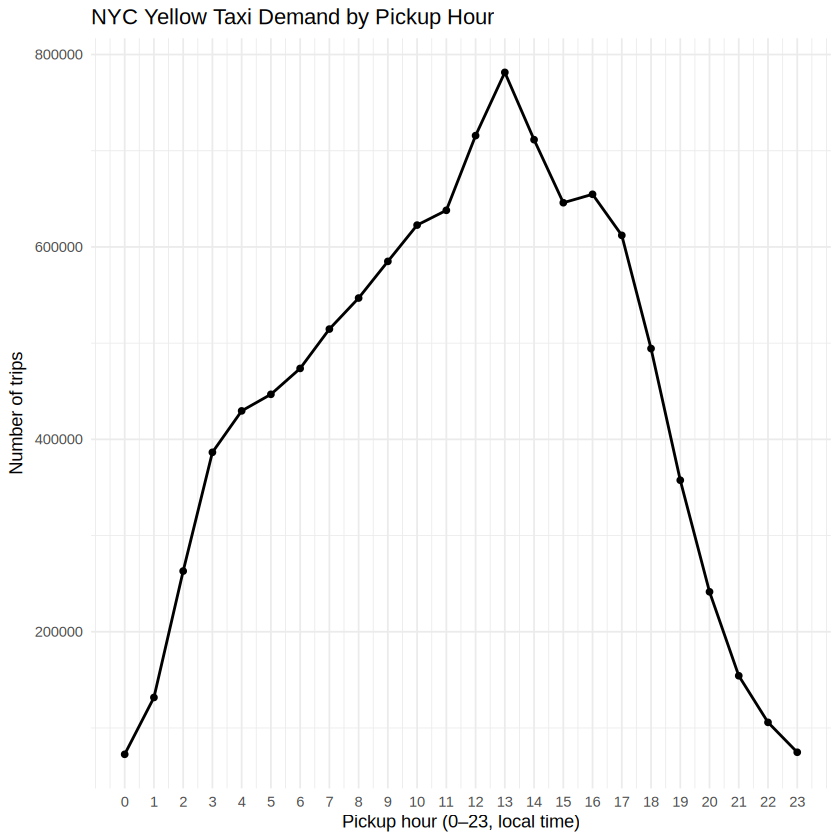

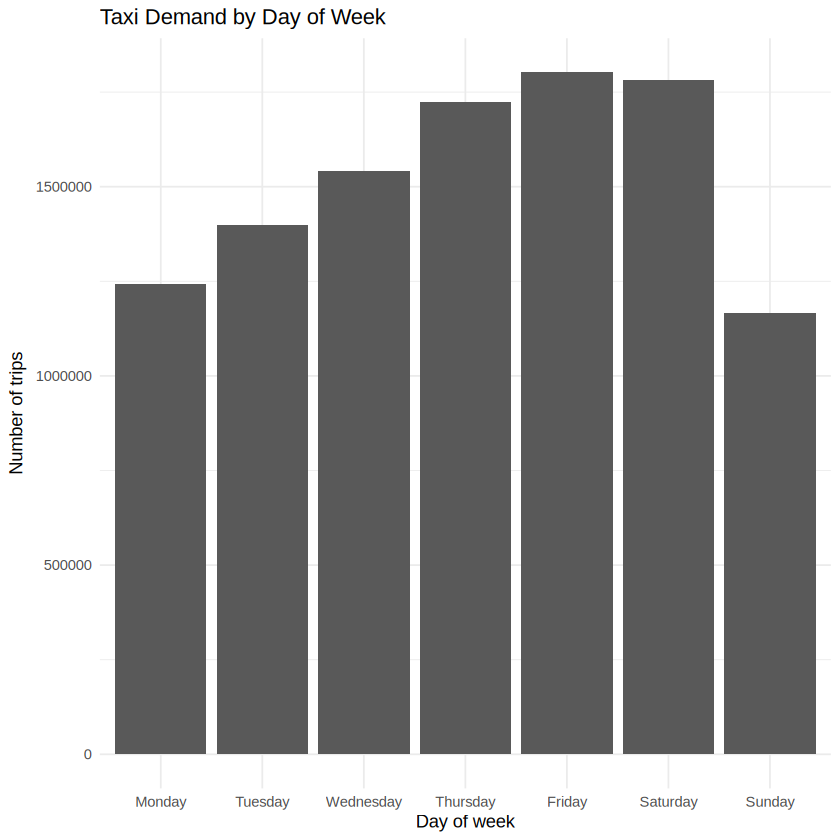

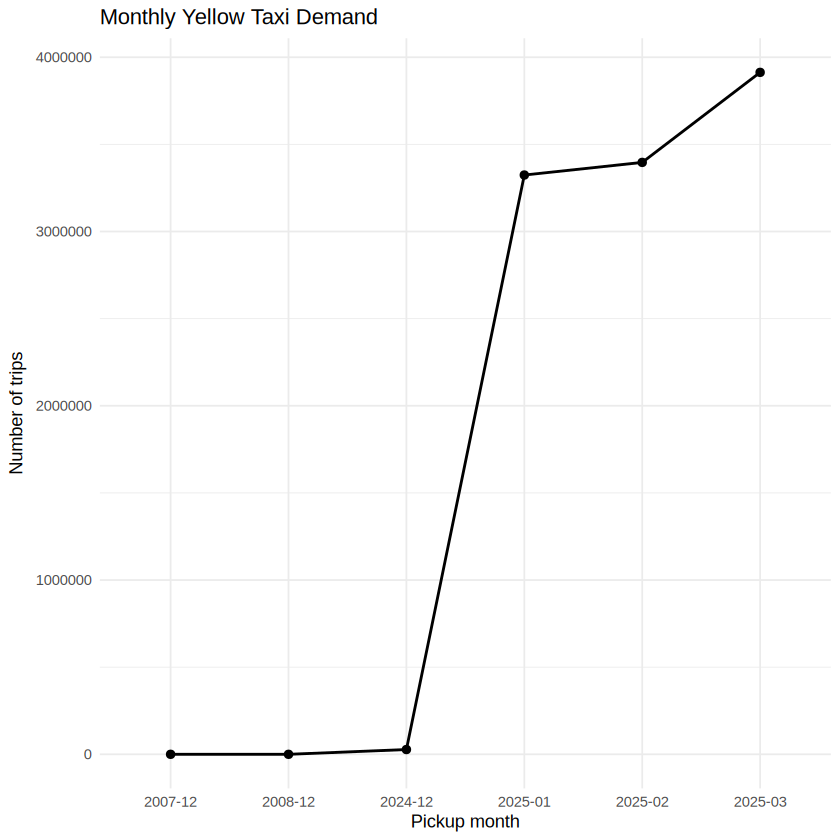

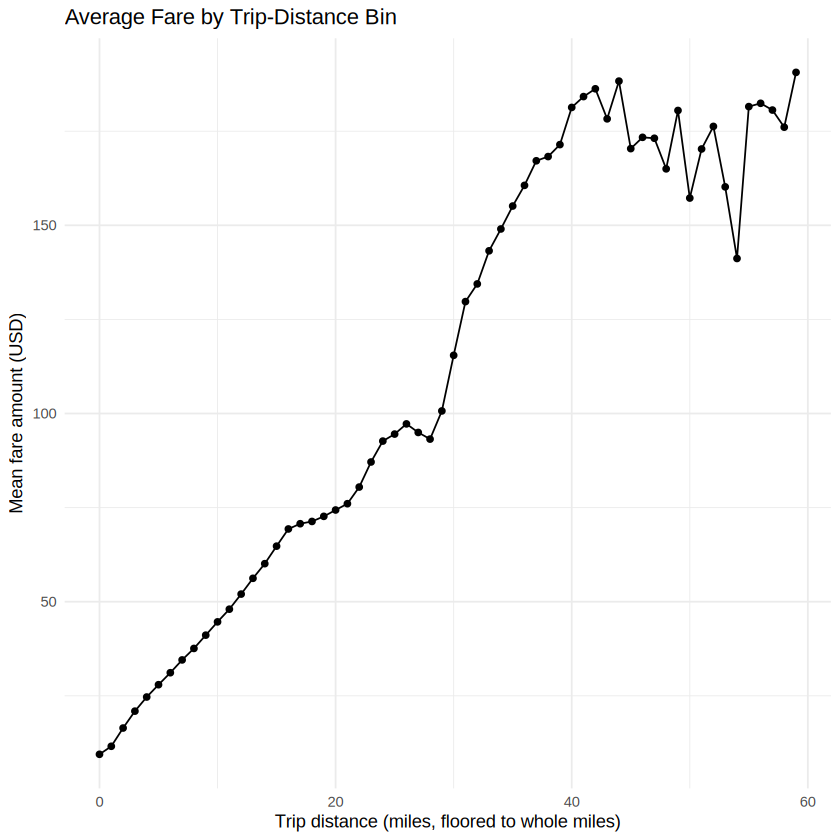

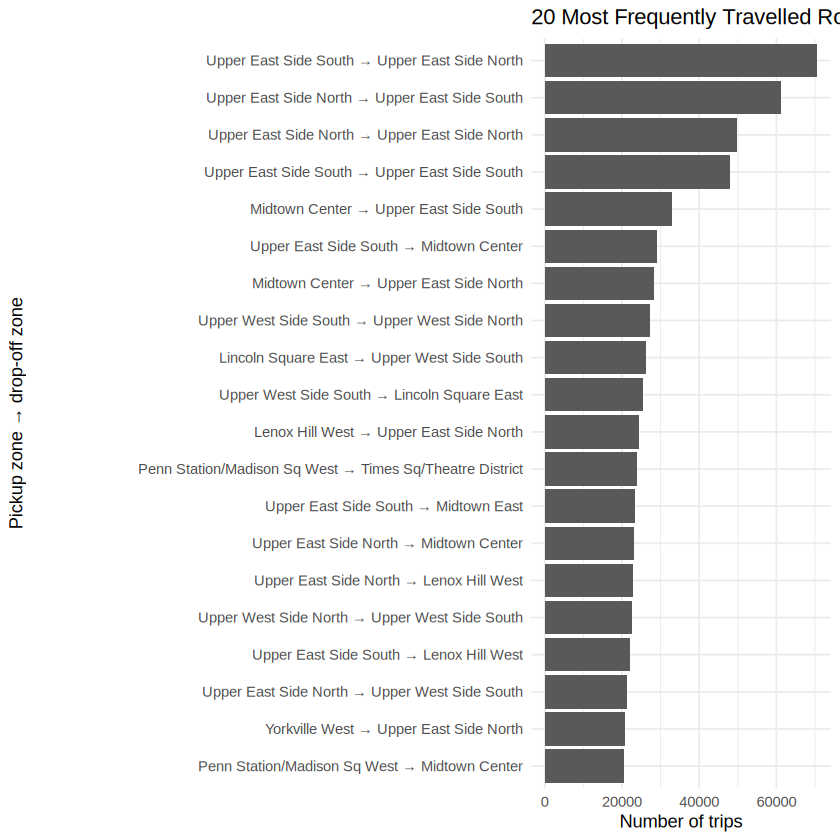

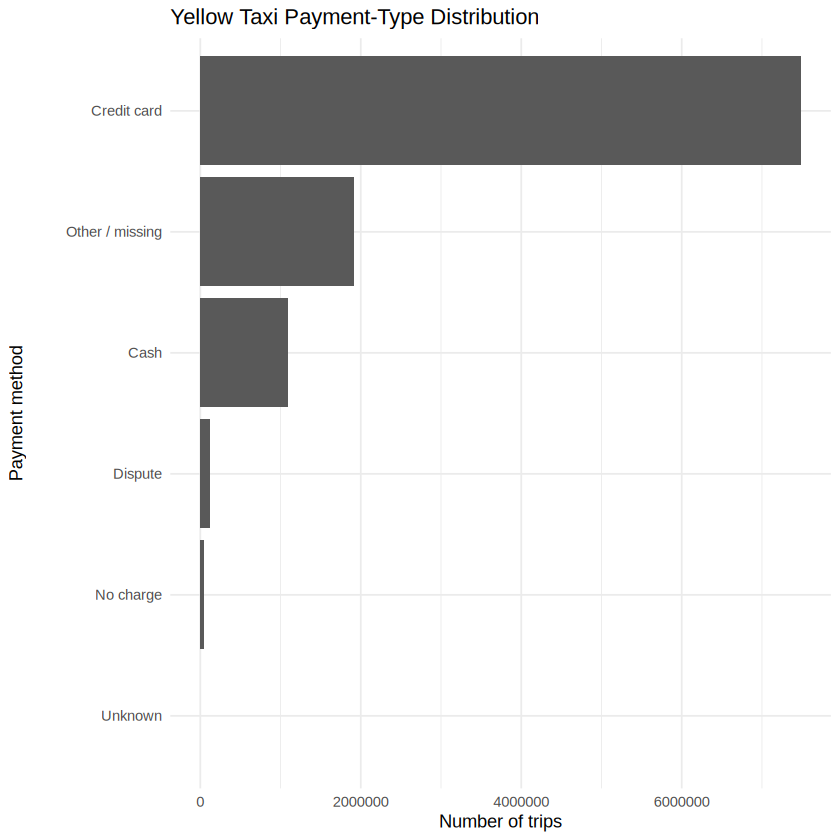

In [18]:
ggplot(trips_by_hour, aes(x = pickup_hour, y = trip_count)) +
  geom_line(linewidth = 0.8) + geom_point(size = 1.5) +
  scale_x_continuous(breaks = 0:23) +
  labs(title = "NYC Yellow Taxi Demand by Pickup Hour",
       x = "Pickup hour (0–23, local time)", y = "Number of trips") +
  theme_minimal()

ggplot(trips_by_weekday, aes(x = pickup_weekday, y = trip_count)) +
  geom_col() +
  labs(title = "Taxi Demand by Day of Week",
       x = "Day of week", y = "Number of trips") +
  theme_minimal()

ggplot(monthly_summary, aes(x = pickup_month, y = trip_count, group = 1)) +
  geom_line(linewidth = 0.8) + geom_point(size = 2) +
  labs(title = "Monthly Yellow Taxi Demand",
       x = "Pickup month", y = "Number of trips") +
  theme_minimal()

ggplot(distance_fare_summary, aes(x = distance_bin, y = mean_fare)) +
  geom_line() + geom_point(size = 1.5) +
  labs(title = "Average Fare by Trip-Distance Bin",
       x = "Trip distance (miles, floored to whole miles)",
       y = "Mean fare amount (USD)") +
  theme_minimal()

top_route_plot <- copy(top_routes)
top_route_plot[, route := paste0(pickup_zone, " → ", dropoff_zone)]
ggplot(top_route_plot, aes(x = reorder(route, trip_count), y = trip_count)) +
  geom_col() + coord_flip() +
  labs(title = "20 Most Frequently Travelled Routes",
       x = "Pickup zone → drop-off zone", y = "Number of trips") +
  theme_minimal()

payment_totals <- trips[, .(trip_count = .N), by = payment_method][order(-trip_count)]
ggplot(payment_totals, aes(x = reorder(payment_method, trip_count), y = trip_count)) +
  geom_col() + coord_flip() +
  labs(title = "Yellow Taxi Payment-Type Distribution",
       x = "Payment method", y = "Number of trips") +
  theme_minimal()

## Functional programming vs vectorized R vs data.table

In [19]:
# Base/vectorized R implementation
base_hour_count <- function(d) {
  tabulate(d$pickup_hour + 1L, nbins = 24L)
}

# data.table grouped implementation
datatable_hour_count <- function(d) {
  out <- d[, .N, by = pickup_hour]
  result <- integer(24)
  result[out$pickup_hour + 1L] <- out$N
  result
}

# lapply: count trips for each hour by repeated filtering
lapply_hour_count <- function(d) {
  unlist(lapply(0:23, function(h) sum(d$pickup_hour == h, na.rm = TRUE)),
         use.names = FALSE)
}

# purrr::map: equivalent repeated operation
map_hour_count <- function(d) {
  unlist(purrr::map(0:23, ~sum(d$pickup_hour == .x, na.rm = TRUE)),
         use.names = FALSE)
}

# apply() demonstration on a small 24-row summary matrix
hour_matrix <- as.matrix(trips_by_hour[, .(pickup_hour, trip_count)])
apply(hour_matrix, 2, mean)

# Verify all methods return equivalent counts.
stopifnot(
  identical(as.integer(base_hour_count(trips)), as.integer(datatable_hour_count(trips))),
  identical(as.integer(base_hour_count(trips)), as.integer(lapply_hour_count(trips))),
  identical(as.integer(base_hour_count(trips)), as.integer(map_hour_count(trips)))
)

benchmark_size <- min(nrow(trips), 500000L)
benchmark_data <- trips[seq_len(benchmark_size)]
bench_functional <- microbenchmark(
  vectorized = base_hour_count(benchmark_data),
  data_table = datatable_hour_count(benchmark_data),
  lapply = lapply_hour_count(benchmark_data),
  purrr_map = map_hour_count(benchmark_data),
  times = 5L
)
print(bench_functional)
summary(bench_functional)[, c("expr", "min", "median", "mean", "max")]

pickup_hour  trip_count 
       11.5    444211.2

Unit: milliseconds
       expr       min        lq      mean    median        uq       max neval
 vectorized  1.351432  1.378260  1.445613  1.409860  1.419430  1.669081     5
 data_table  8.772538  8.903588  8.917597  8.921647  8.958896  9.031315     5
     lapply 32.183259 32.351615 35.013869 32.710508 33.464104 44.359857     5
  purrr_map 32.362186 32.401428 32.998095 32.835070 33.184273 34.207516     5


expr,min,median,mean,max
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
vectorized,1.351432,1.409860,1.445613,1.669081
data_table,8.772538,8.921647,8.917597,9.031315
lapply,32.183259,32.710508,35.013869,44.359857
purrr_map,32.362186,32.835070,32.998095,34.207516


## Sequential vs parallel processing with foreach and doParallel



In [20]:
month_parts <- split(trips, by = "source_month", keep.by = TRUE)

summarize_partition <- function(d) {
  d[, .(
    trip_count = .N,
    total_revenue = sum(total_amount, na.rm = TRUE),
    mean_fare = mean(fare_amount, na.rm = TRUE),
    mean_distance = mean(trip_distance, na.rm = TRUE)
  ), by = source_month]
}

seq_timing <- system.time({
  sequential_result <- rbindlist(lapply(month_parts, summarize_partition))
})

available_cores <- parallel::detectCores(logical = TRUE)
if (is.na(available_cores)) available_cores <- 2L
workers <- max(1L, min(2L, available_cores - 1L, length(month_parts)))

parallel_result <- NULL
parallel_timing <- NULL
if (workers >= 2L && length(month_parts) >= 2L) {
  cl <- parallel::makeCluster(workers)
  doParallel::registerDoParallel(cl)
  parallel_timing <- system.time({
    parallel_result <- foreach(part = month_parts,
                               .combine = rbind,
                               .packages = "data.table") %dopar% {
      part <- as.data.table(part)
      part[, .(
        trip_count = .N,
        total_revenue = sum(total_amount, na.rm = TRUE),
        mean_fare = mean(fare_amount, na.rm = TRUE),
        mean_distance = mean(trip_distance, na.rm = TRUE)
      ), by = source_month]
    }
  })
  parallel::stopCluster(cl)
  foreach::registerDoSEQ()
} else {
  message("Parallel comparison skipped: need at least two partitions and two workers.")
}

print(sequential_result)
print(seq_timing)
if (!is.null(parallel_result)) {
  print(parallel_result)
  print(parallel_timing)
  speedup <- unname(seq_timing[["elapsed"]] / parallel_timing[["elapsed"]])
  cat("Sequential elapsed (seconds):", seq_timing[["elapsed"]], "\n")
  cat("Parallel elapsed (seconds):", parallel_timing[["elapsed"]], "\n")
  cat("Speedup (sequential / parallel):", round(speedup, 3), "x\n")
  cat("Parallel faster:", speedup > 1, "\n")
  # Compare results after sorting to verify analytical equivalence.
  setorder(sequential_result, source_month)
  setorder(parallel_result, source_month)
  print(all.equal(sequential_result, parallel_result, check.attributes = FALSE))
}

Parallel comparison skipped: need at least two partitions and two workers.



   source_month trip_count total_revenue mean_fare mean_distance
         <char>      <int>         <num>     <num>         <num>
1:      2025-01    3330645      90329931  18.32549      5.387085
2:      2025-02    3394391      90512275  18.16076      5.690174
3:      2025-03    3936033     110177524  19.28498      5.946741
   user  system elapsed 
  0.517   0.000   0.526 


In [21]:
# Benchmark Base R aggregation vs data.table

benchmark_n <- min(nrow(trips), 500000L)
bench_data <- trips[seq_len(benchmark_n)]

base_aggregate <- function(d) {
  aggregate(total_amount ~ pickup_hour, data = d, FUN = sum)
}
dt_aggregate <- function(d) {
  d[, .(total_amount = sum(total_amount, na.rm = TRUE)), by = pickup_hour]
}

# Verify equivalent aggregate values (sort rows before comparing).
base_result <- as.data.table(base_aggregate(bench_data))
dt_result <- dt_aggregate(bench_data)
setorder(base_result, pickup_hour)
setorder(dt_result, pickup_hour)
stopifnot(isTRUE(all.equal(base_result, dt_result, check.attributes = FALSE)))

bench_aggregation <- microbenchmark(
  base_R_aggregate = base_aggregate(bench_data),
  data_table = dt_aggregate(bench_data),
  times = 5L
)
print(bench_aggregation)
print(summary(bench_aggregation)[, c("expr", "min", "median", "mean", "max")])

full_base_time <- system.time(base_aggregate(trips))
full_dt_time <- system.time(dt_aggregate(trips))
data.frame(
  implementation = c("Base R aggregate", "data.table"),
  elapsed_seconds = c(full_base_time[["elapsed"]], full_dt_time[["elapsed"]]),
  dataset_rows = nrow(trips)
)

Unit: milliseconds
             expr       min        lq      mean    median       uq       max
 base_R_aggregate 134.86431 134.92532 142.13753 135.45015 137.9220 167.52589
       data_table  10.50363  10.56561  10.83715  10.92419  10.9939  11.19842
 neval
     5
     5
              expr       min    median      mean       max
1 base_R_aggregate 134.86431 135.45015 142.13753 167.52589
2       data_table  10.50363  10.92419  10.83715  11.19842


implementation,elapsed_seconds,dataset_rows
<chr>,<dbl>,<int>
Base R aggregate,3.973,10661069
data.table,0.223,10661069


In [22]:
# Memory utilization and benchmark comparison

memory_comparison <- data.frame(
  object = c("cleaned trips", "zone lookup", "hourly summary", "monthly summary"),
  approximate_MiB = c(
    as.numeric(object.size(trips)),
    as.numeric(object.size(zones)),
    as.numeric(object.size(trips_by_hour)),
    as.numeric(object.size(monthly_summary))
  ) / 1024^2
)
print(memory_comparison)

benchmark_summary <- as.data.frame(summary(bench_functional))
benchmark_summary <- benchmark_summary[, intersect(
  c("expr", "min", "lq", "mean", "median", "uq", "max"), names(benchmark_summary)
)]
print(benchmark_summary)

           object approximate_MiB
1   cleaned trips  1789.470184326
2     zone lookup     0.027305603
3  hourly summary     0.001548767
4 monthly summary     0.002433777
        expr       min        lq      mean    median        uq       max
1 vectorized  1.351432  1.378260  1.445613  1.409860  1.419430  1.669081
2 data_table  8.772538  8.903588  8.917597  8.921647  8.958896  9.031315
3     lapply 32.183259 32.351615 35.013869 32.710508 33.464104 44.359857
4  purrr_map 32.362186 32.401428 32.998095 32.835070 33.184273 34.207516


## Conclusion

The experiment analyzed approximately 11.2 million NYC Yellow Taxi records using R to identify travel patterns, fare trends, revenue, and payment preferences. Data preprocessing, zone joining, and visualization were performed using data.table and ggplot2. Vectorized operations achieved the best performance, with a median execution time of 1.41 seconds, compared with 8.92 seconds for data.table and approximately 32.8 seconds for functional approaches. The experiment demonstrated that vectorization is efficient for suitable calculations, while data.table is useful for large-scale data manipulation. Overall, selecting appropriate techniques improves execution speed, memory efficiency, and scalability.